# Get diaObjectIds classified by ALeRCE as VS and Bogus.

This notebooks saves in your Google Drive a csv file with the following columns: `oid, ra, dec, ndiasources, class_name, probability`.

*   `class_name = {'VS', 'bogus'}`
*   `probability >= 0.8`
*   `ndiasources > 1 `

The query takes a little bit of time ~5min








# Install

In [ ]:
! pip install alerce
! pip install pyvo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 18.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 21.9 MB/s eta 0:00:00


# Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pyvo as vo
import os
import time
import threading
from concurrent.futures import ThreadPoolExecutor

# Initalize Alerce client

In [ ]:
from alerce.core import Alerce
alerce = Alerce()

# Initialize TAP service

In [ ]:
tap_service_url = "https://tap.alerce.online/tap"
service = vo.dal.TAPService(tap_service_url)

## query individually the top 200K objects that are classified as bogus or VS by alerce with a probability >= 0.8,  (200K for each class)

200K is max amount allowed per query


In [ ]:
# Write the ADQL query
query = """
      SELECT DISTINCT TOP 200000
          obj.oid, obj.ra, obj.dec, obj.ndiasources, tax.class_name, prob.probability
      FROM alerce_tap.lsst_dia_object AS obj
      JOIN alerce_tap.probability AS prob ON obj.oid = prob.oid
      JOIN alerce_tap.taxonomy AS tax ON prob.class_id = tax.class_id
      WHERE tax.class_name = 'bogus'
        AND prob.probability >= 0.8 AND prob.ranking=1
        AND obj.ndiasources > 1 AND tax.classifier_id=2
"""

# Execute the synchronous or asynchronous TAP job
df_bogus = service.search(query).to_table().to_pandas()

In [ ]:
df_bogus.shape

(200000, 6)

In [ ]:
df_bogus

,oid,ra,dec,ndiasources,class_name,probability
0,170019696010067995,53.190706,-29.072177,8,bogus,0.943377
1,170019696054632535,53.375410,-27.199662,2,bogus,0.924038
2,170019696077701139,52.591362,-26.807001,7,bogus,0.867713
3,170019696205103136,52.676541,-26.872335,2,bogus,0.867947
4,170019696205103136,52.676541,-26.872335,2,bogus,0.904031
...,...,...,...,...,...,...
199995,170591514393576086,307.362176,-14.532750,2,bogus,0.846404
199996,170591514393576094,307.384336,-14.565598,3,bogus,0.807220
199997,170591514394099740,307.163989,-14.232130,2,bogus,0.923641
199998,170591514394099747,307.166617,-14.231657,3,bogus,0.818611


In [ ]:
# Write the ADQL query
query = """
      SELECT DISTINCT TOP 200000
          obj.oid, obj.ra, obj.dec, obj.ndiasources, tax.class_name, prob.probability
      FROM alerce_tap.lsst_dia_object AS obj
      JOIN alerce_tap.probability AS prob ON obj.oid = prob.oid
      JOIN alerce_tap.taxonomy AS tax ON prob.class_id = tax.class_id
      WHERE tax.class_name = 'VS'
        AND prob.probability >= 0.8 AND prob.ranking=1
        AND obj.ndiasources > 1 AND tax.classifier_id=2
"""

# Execute the synchronous or asynchronous TAP job
df_vs = service.search(query).to_table().to_pandas()

In [ ]:
df_vs.shape

(29687, 6)

### merge bogus and VS results

In [ ]:
df_bogus.shape

(200000, 6)

In [ ]:
df_vs.shape

(29687, 6)

In [ ]:
df_all = pd.concat([df_bogus, df_vs])


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path_save = "/content/drive/MyDrive/hackathon_colombia_oct_2026"

There are duplicated oid, some alerce parameter I'm not taking into account when doing the query, but it's ok, it's not so bad, I will just drop them

In [ ]:
df_all = df_all.drop_duplicates(subset=['oid']).reset_index(drop=True)

In [ ]:
df_all.shape

(177839, 6)

### SAVE CSV FILE

uncomment to save csv file. Be aware of changing the `path_save` (a few line above) to your like, same with the name of the file

In [ ]:
# df_all.to_csv(os.path.join(path_save,'alerce_vs_bogus_classifier2_probgt08.csv.gz'), index=False, compression='gzip')

## Some plots

<Axes: xlabel='class_name', ylabel='probability'>

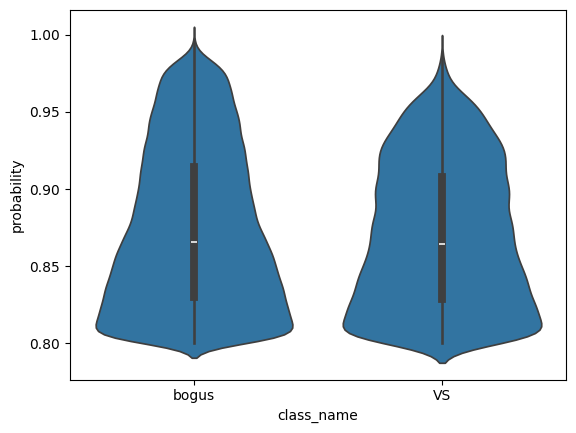

In [ ]:
sns.violinplot(data=df_all, x="class_name", y="probability")

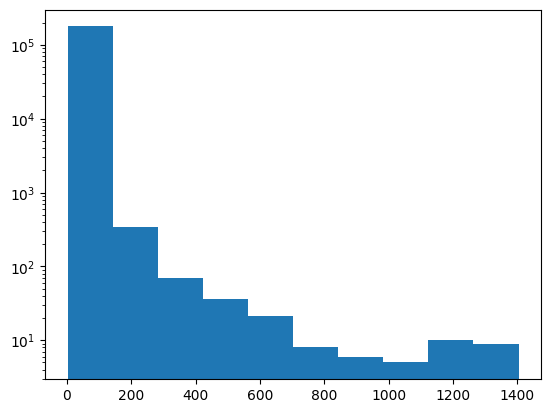

In [ ]:
plt.hist(df_all['ndiasources']);
plt.yscale('log')

In [ ]:
df_all['class_name'].value_counts()


,count
class_name,
bogus,156128
VS,21711


In [ ]:
df_all.query('ndiasources > 2')['class_name'].value_counts()

,count
class_name,
bogus,69462
VS,10474


<Axes: xlabel='class_name', ylabel='ndiasources'>

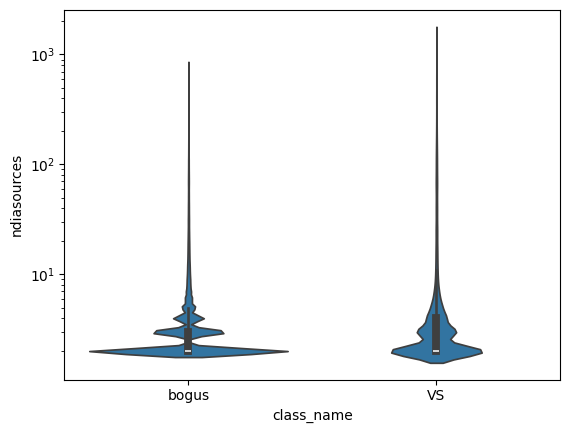

In [ ]:
sns.violinplot(data=df_all, x="class_name", y="ndiasources", log_scale=True)


# Here I show how to use ALeRCE to save the stamps/images for every VS object, using the respective oid, the image is saved in your Google Drive.

This works, but `alerce.client()` keeps dying all the time (they are protecting their servers from massive downloads), so to save the stamps I moved to another broker, Fink. See notebook NAME

## get object ids from previous results

In [ ]:
oid_list = df_all['oid'].tolist()
len(oid_list)

177839

In [ ]:
path_save = "/content/drive/MyDrive/{your_path_to_save_images}"

## Save stamps for each object id.

Retry download by re-initializing the alerce client

## Just 10 objects

In [ ]:
client_lock = threading.Lock()

def reinitialize_global_client():
    """Safely replaces the global client instance across all threads."""
    global client
    with client_lock:
        print("Network or API issue detected. Reinitializing ALeRCE client...")
        try:
            client = Alerce()
            print("Client reinitialized successfully.")
        except Exception as e:
            print(f"Critial: Failed to reinitialize client: {e}")

def download_stamp_with_retry(oid, retries=3, backoff_in_seconds=2):
    """
    Attempts to download stamps. If it fails, it reinitializes the
    global client and retries up to the specified limit.
    """
    for attempt in range(1, retries + 1):
        try:
            # Always read the current global client instance
            stamps = client.get_stamps(oid=oid, survey="lsst")
            os.makedirs(os.path.join(path_save,f"{oid}"), exist_ok=True)

            np.save(os.path.join(path_save,f"{oid}/{oid}_science_cutout.npy"), stamps['cutoutScience'].data)
            np.save(os.path.join(path_save,f"{oid}/{oid}_template_cutout.npy"), stamps['cutoutTemplate'].data)
            np.save(os.path.join(path_save,f"{oid}/{oid}_difference_cutout.npy"), stamps['cutoutDifference'].data)

            print(f"Successfully downloaded stamps for {oid} on attempt {attempt}")
            return oid, 1
        except Exception as e:
            print(f"Attempt {attempt}/{retries} failed for {oid}. Error: {e}")

            if attempt == retries:
                print(f"Max retries reached. Giving up on {oid}.")
                return oid, None

            # Reinitialize the client since the prior connection failed
            reinitialize_global_client()

            # Exponential backoff pause before retrying the stamp request
            sleep_time = backoff_in_seconds ** attempt
            time.sleep(sleep_time)

# Fetch stamps concurrently using threads
bulk_stamps = {}
with ThreadPoolExecutor(max_workers=5) as executor:
    results = executor.map(lambda oid: download_stamp_with_retry(oid), oid_list[:10])
    for oid, stamps in results:
        if stamps:
            bulk_stamps[oid] = 1
        else:
          bulk_stamps[oid] = 0

print(f"Successfully saved {len(bulk_stamps)} cutouts!")


Attempt 1/3 failed for 170019696010067995. Error: name 'client' is not defined
Network or API issue detected. Reinitializing ALeRCE client...
Attempt 1/3 failed for 170019696054632535. Error: name 'client' is not defined
Attempt 1/3 failed for 170019696077701139. Error: name 'client' is not defined
Client reinitialized successfully.
Network or API issue detected. Reinitializing ALeRCE client...
Client reinitialized successfully.
Network or API issue detected. Reinitializing ALeRCE client...
Client reinitialized successfully.
Successfully downloaded stamps for 170019696205103136 on attempt 1
Successfully downloaded stamps for 170019696205103136 on attempt 1
Successfully downloaded stamps for 170019696077701139 on attempt 2
Successfully downloaded stamps for 170019696054632535 on attempt 2
Successfully downloaded stamps for 170019696010067995 on attempt 2
Successfully downloaded stamps for 170019696254910754 on attempt 1
Successfully downloaded stamps for 170019696255435832 on attempt 1


In [ ]:
ß